# cpbench workbench

The interactive entry point for everything except large sweeps, which run on HPC. Work top to bottom:

1. **Dataset:** write a specification, generate the data and look at it.
2. **Detectors on raw features:** choose detectors and raw window features, run them, and see their decisions against the truth.
3. **Feature learners:** write the learners to fit, train them, and re-run the same detectors on the learnt features.

Edit the cells marked ✏️ and re-run from there. Everything is cached under `RUNS`: re-running a cell only computes what changed, whether a new detector, a new learner or a new dataset.

In [1]:
# !conda install pyarrow fastparquet -y   # not needed (results are CSV); reinstalling inside a running kernel breaks pyarrow

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cpbench import Benchmark, make_learner, make_detector
from cpbench.data import Dataset, available, short
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
from cpbench import viz
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
RUNS = "cpbench_runs_workbench"
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

## 1. Dataset

A dataset is a pipeline: a **regime** process, **sources** and **transforms**, plus a seed. Per-channel standardisation is added at the end. Every timescale is in samples.

- **Sources are linear signals:** `level`, `white`, `ar` (AR(1)/AR(2)), `oscillator` (damped, or a pure sine with `damp=1, sigma=0, amplitude=1`), `trend` and `impulses`. There are also two structured sources, `phase` and `transition`, and a `composite` that bundles sources with their own transforms.
- **Any numeric parameter can depend on the regime,** and a change point is exactly that:
  - `0.8`: the same in every regime;
  - `[0.2, 0.9]`: one value per regime;
  - `{base: 0.4, spread: 0.5}`: values spread across the regimes, permuted per channel;
  - `{channels: [...]}`: per-channel values, the same in every regime.
- **Nonlinearities are transforms:**
  - `pointwise` (triangle, sign/square, abs, tanh, cube, skew; optionally mirrored per regime);
  - `linear` (explicit or random matrices, optionally per regime);
  - `delay` (per-regime lags);
  - `bandpass`, `couplings`, `saturate`;
  - sensor effects: `gain_drift`, `lowpass`, `volatility`, `noise`, `wander`, `outliers`, `dropout`, `time_warp`.
- **Gradual change points:** `regime=dict(..., ramp=200)` blends parameters linearly over 200 samples around each switch.

A source whose parameters depend on the regime counts as **signal**, any other source as **nuisance**. The dataset is identified by its construction (`ds.info.id`). The standard change types are written out in `cpbench/configs/grid_synthetic.yaml`.

The next cell lists every component and shows some defaults. Unknown parameter names raise an error.

In [14]:
print("regimes:   ", available("regime"))
print("sources:   ", available("source"))
print("transforms:", available("transform"))
print("\ndefaults:", {n: short("source", {"type": n}) for n in ["ar", "oscillator", "level"]})
from cpbench.data.registry import REGISTRIES
for n in ["ar", "oscillator", "trend"]:
    print(f"  {n}: {REGISTRIES['source'].defaults(n)}")

regimes:    ['markov', 'none', 'scripted', 'single_cp']
sources:    ['ar', 'composite', 'impulses', 'level', 'oscillator', 'phase', 'transition', 'trend', 'white']
transforms: ['bandpass', 'couplings', 'delay', 'dropout', 'gain_drift', 'linear', 'lowpass', 'noise', 'outliers', 'pointwise', 'project', 'saturate', 'time_warp', 'volatility', 'wander']

defaults: {'ar': 'ar', 'oscillator': 'oscillator', 'level': 'level'}
  ar: {'scale': 1.0, 'regime': 'main', 'd': 1, 'phi': 0.8, 'phi2': 0.0, 'sigma': 1.0, 'corr': 0.0, 'unit_variance': True}
  oscillator: {'scale': 1.0, 'regime': 'main', 'd': 1, 'freq': 0.05, 'damp': 0.97, 'sigma': 1.0, 'amplitude': 0.0, 'quadrature': False, 'unit_variance': True}
  trend: {'scale': 1.0, 'regime': 'main', 'd': 1, 'drift': 0.0, 'sigma': 0.0, 'kappa': 0.0}


### Signal generation options

Each line of `sources` adds channels. A parameter given as a list (one value per regime) makes that source part of the **signal**; scalar parameters make it a **nuisance**. `transforms` then act on all channels, in order (`channels=[i]` restricts one to some channels).

| change you want | source / transform (K=2) |
|---|---|
| mean step | `dict(type="level", mu=[-1, 1])` |
| drift / slope | `dict(type="trend", drift=[-0.01, 0.01], kappa=0.001)` (kappa keeps it bounded) |
| variance | `dict(type="ar", phi=0.8, sigma=[0.5, 2.0])` |
| autocorrelation only | `dict(type="ar", phi=[0.2, 0.9])` (variance kept at 1) |
| frequency of a pure sine | `dict(type="oscillator", freq=[0.01, 0.03], damp=1.0, sigma=0.0, amplitude=1.0)` |
| frequency of a noisy rhythm | `dict(type="oscillator", freq=[0.05, 0.15], damp=0.97)` |
| square / triangle wave | oscillator + `dict(type="pointwise", fn="sign")` or `fn="triangle"` |
| amplitude | source + `dict(type="linear", weights=[[[0.5]], [[2.0]]])` (one matrix per regime) |
| cross-channel correlation | `dict(type="white", d=2, corr=[0.0, 0.9])`, or `linear` with per-regime matrices |
| lead-lag | copies of one channel + `dict(type="delay", lags=[[0, 4], [4, 0]])` |
| higher-order moments only | `dict(type="pointwise", fn="skew", mirror=[0, 1])` on a Gaussian source |
| phase coupling / hidden transitions | `dict(type="phase")`, `dict(type="transition")` (nothing visible in one window) |
| gradual instead of abrupt | `regime=dict(..., ramp=200)` |

Combining: list several sources (stacked as channels), sum them into one channel with `dict(type="linear", weights=[[1, 1]])`, or bundle them with `dict(type="composite", sources=[...], transforms=[...], combine="sum")`. Nuisances (regime-independent): `dict(type="ar", phi=0.999)` slow factors, `impulses`, `white`. Corruption: `project`, `noise`, `couplings`, `saturate`, `gain_drift`, `lowpass`, `volatility`, `wander`, `outliers`, `dropout`, `time_warp`.

In [15]:
# ✏️ dataset specification (same structure as a YAML file; see cpbench/configs/grid_synthetic.yaml for more recipes)
DATASET = dict(
    regime=dict(type="markov", K=2, dwell=320, ramp=0),            # K regimes, mean segment length; ramp>0: gradual changes
    sources=[
        dict(type="level", mu=[-2.5, 2.5]),                        # channel 0: a step (mean change)
        # dict(type="oscillator", freq=[0.02, 0.05], damp=1.0,       # channel 1: a pure sine whose frequency changes
        #      sigma=0.0, amplitude=1.0),
        # dict(type="ar", d=2, phi=[0.2, 0.9]),                    # an autocorrelation change (variance kept fixed)
        # dict(type="ar", d=3, phi=0.999, scale=0.8),              # a nuisance: slow regime-independent factors
        # dict(type="impulses", rate=0.02, scale=0.8),             # a nuisance: sparse heavy-tailed events
    ],
    transforms=[                                                   # nonlinearities and corruption, applied in order
        # dict(type="pointwise", fn="triangle", channels=[1]),     # sine -> triangle (fn="sign": square wave)
        # dict(type="linear", weights=[[1, 1]]),                     # observed = step + sine (one channel)
        # dict(type="noise", sigma=0.3),
        # dict(type="project", D=64),                              # random mixing into 64 channels
    ],
    standardize=False,                                             # keep the original units
    seed=0,
    splits=dict(test=[4, 16000], val=[2, 9600]),                   # [series, samples]: small for interactive work
)
ds = Dataset(DATASET)
data = ds.test_set()
print(ds.info.id)
print(f"K={ds.K}, observed channels D={ds.D}, test split {data['obs'].shape}")

markov(K=2)|level(mu=[-2.5,2.5])|-|-#a3f532f0
K=2, observed channels D=1, test split (4, 16000, 1)


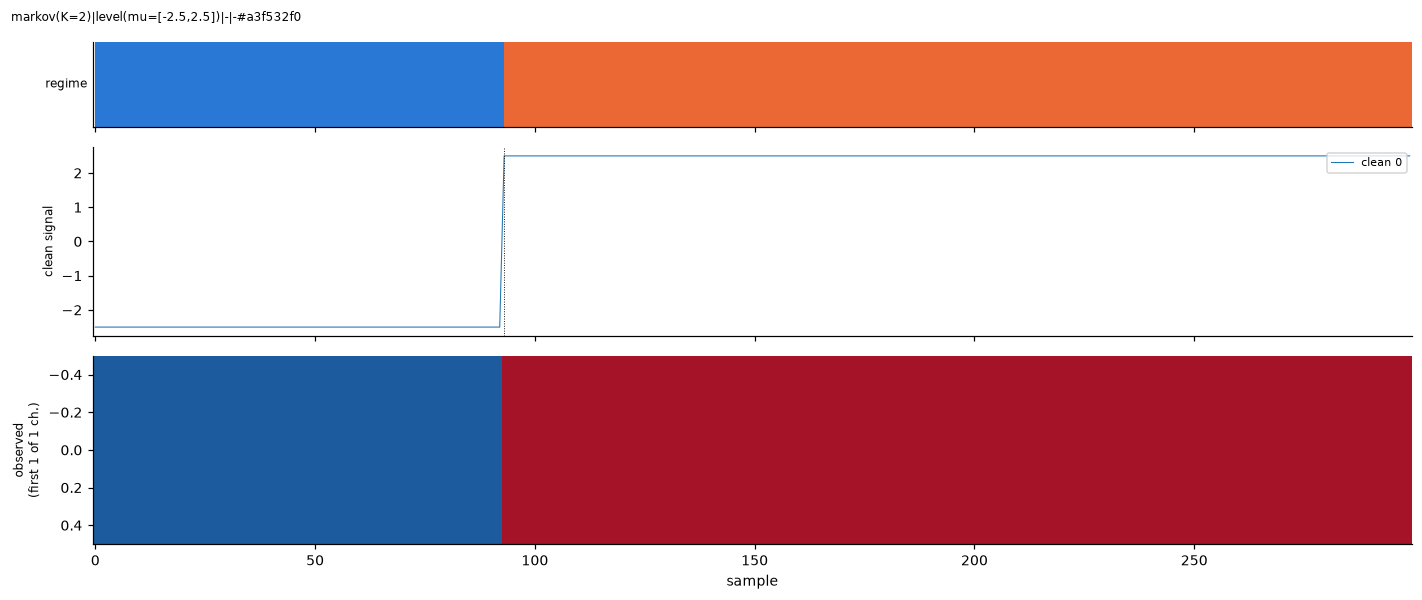

In [16]:
# one test series: true regimes, the clean regime-driven signal and the observed channels
viz.plot_dataset(ds, data, series=1, n=300)

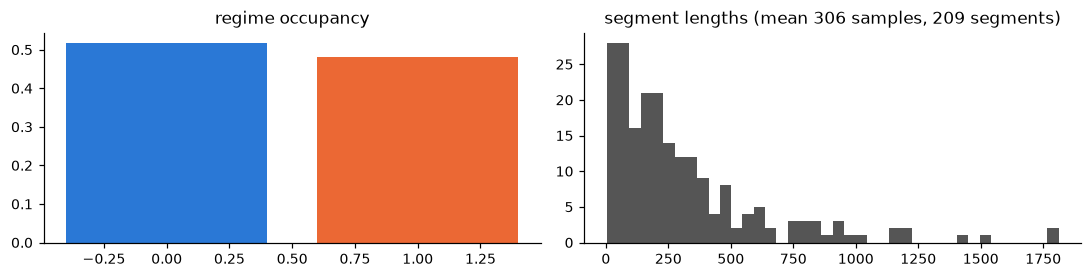

In [17]:
# regime statistics of the test split
S = data["S_s"]
seg = np.concatenate([np.diff(np.r_[0, np.flatnonzero(np.diff(s)) + 1, len(s)]) for s in S])
fig, axs = plt.subplots(1, 2, figsize=(10, 2.6))
axs[0].bar(range(ds.K), np.bincount(S.ravel(), minlength=ds.K) / S.size, color=viz.COLORS[: ds.K]); axs[0].set_title("regime occupancy")
axs[1].hist(seg, bins=40, color="#555"); axs[1].set_title(f"segment lengths (mean {seg.mean():.0f} samples, {len(seg)} segments)")
plt.tight_layout(); plt.show()

## 2. Detectors on raw features

**Detectors** do change-point detection and regime clustering on a sequence of window features. They receive the number of regimes K and are fitted on the series they're given.

**Raw feature learners** (`raw_<feature>`) turn each window into simple statistics: means, log-sd and autocorrelations (`stats`), log spectra, covariances, lagged covariances, co-skewness, bispectrum, or the flattened window. Each feature learner × detector pair is one classical baseline.

The window length is a hyperparameter of the feature learner, in samples. Scoring is at sample level, so windows that straddle a switch cost accuracy.

**Metrics:**
- `acc`: best-permutation balanced accuracy (chance = 1/K); `ari` and `nmi` are also reported.
- `cp_ap`: average precision of change-point detection within ±`margin` samples.
- `cp_f1`, `cp_covering`: at a label-free threshold.

In [18]:
print("detectors:", DETECTORS.available())
print("fixed feature learners:", LEARNERS.available(lambda c: not c.trainable))

detectors: ['arhmm', 'bocpd', 'contrast', 'gmm', 'hmm', 'mmd', 'temporal_excess']
fixed feature learners: ['oracle', 'oracle_clean', 'oracle_hidden', 'raw', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_lagcov', 'raw_mean', 'raw_spectra', 'raw_stats']


In [19]:
# ✏️ detectors (a name, or a dict with parameters) and raw feature learners
DETECTORS_USED = ["gmm", "hmm", "arhmm", dict(type="bocpd", hazard=0.01), "contrast"]
RAW = [make_learner("raw_stats", window=32), make_learner("raw_spectra", window=32), make_learner("raw_stats", window=16)]

bench = Benchmark(ds, detectors=DETECTORS_USED, out=RUNS, log=lambda *a: None)
res_raw = pd.concat([bench.run(f) for f in RAW], ignore_index=True)
res_raw[(res_raw.view == "features") & res_raw.metric.isin(["acc", "cp_ap"])].pivot_table(
    index="features_label", columns=["metric", "detector_label"], values="value").round(3)

metric                  acc                cp_ap                                          
detector_label        arhmm    gmm    hmm  arhmm bocpd(hazard=0.01) contrast    gmm    hmm
features_label                                                                            
raw_spectra           0.507  0.500  0.507  0.550              0.852    0.388  0.056  0.574
raw_stats             0.498  0.957  0.957  0.476              0.883    0.840  0.902  0.902
raw_stats(window=16)  0.499  0.988  0.977  0.945              0.961    0.980  0.927  0.941

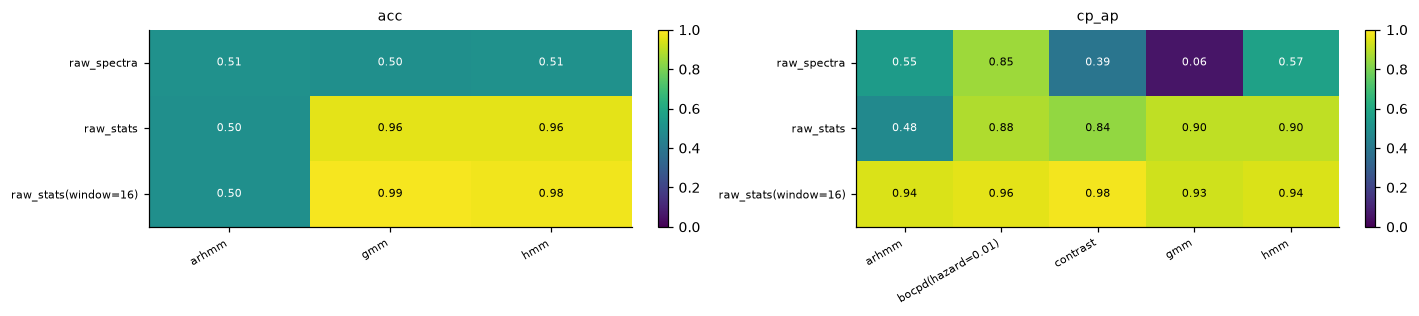

In [20]:
viz.plot_results(res_raw)

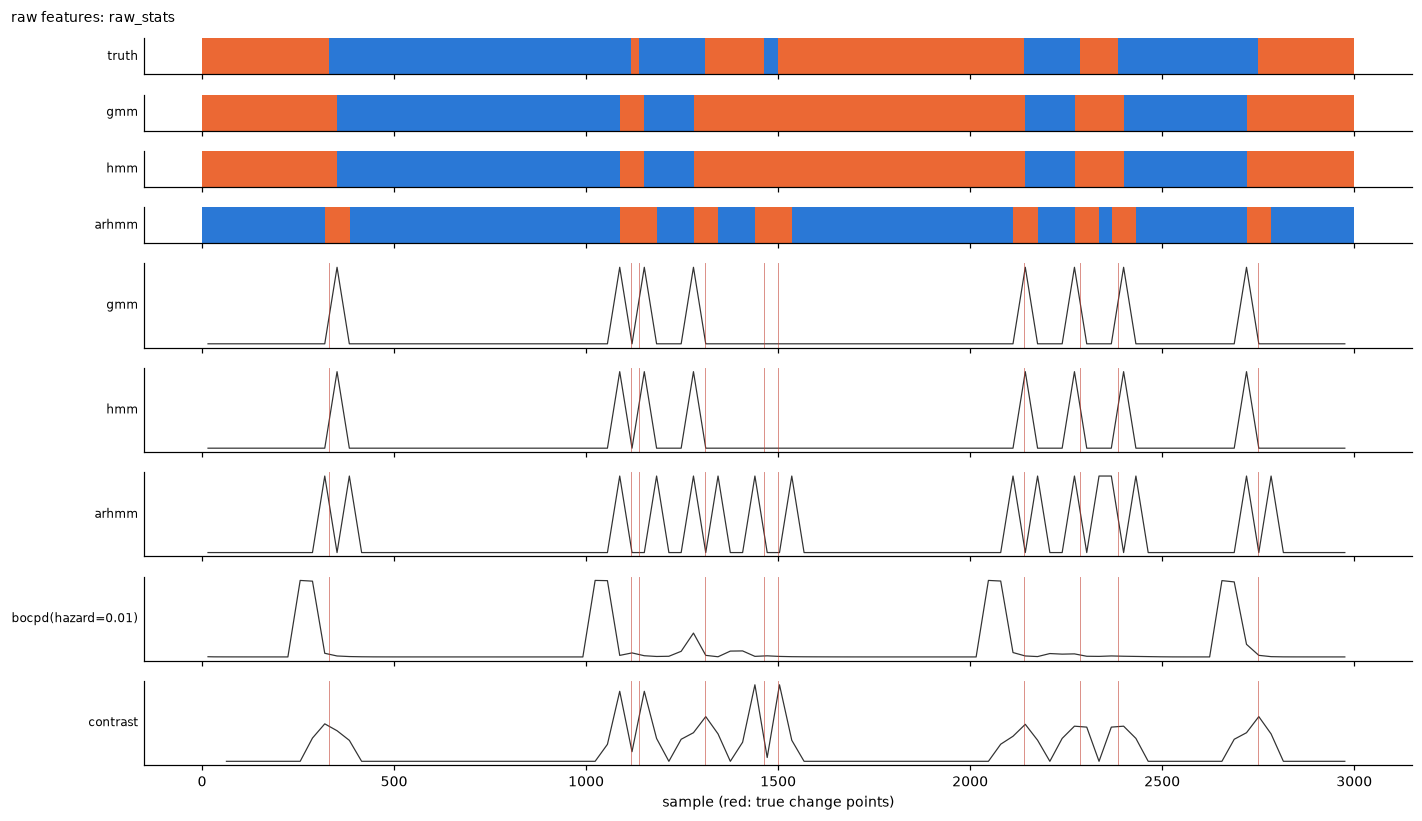

In [21]:
# ✏️ the detectors' decisions on one raw feature learner, against the truth
f = RAW[0]
dec, starts = bench.decisions(f)
viz.plot_decisions(data, dec, starts, f.window, ds.K, title=f"raw features: {f.label()}", n=3000)

## 3. Feature learners

Write the feature learners to fit. Self-supervised learners train on fresh samples of the dataset. Their parameters include:
- `window` and `gap` (samples);
- `steps`, `batch`, `lr`;
- network size (`d`, `H`, `backbone` = tcn / gru / transformer);
- method-specific settings, such as JEPA `design` (shared / separate / separate_full), `predictor` (linear / mlp) and `lam`, or VAE `beta`.

Local training on the Mac is for exploration (a few thousand steps). Long runs belong on HPC (`cpbench/hpc/make_sweep.py`). Fitted learners are saved and reused, and training resumes if `steps` is increased.

The same detectors then run on the learnt features, and the comparison with the raw baselines comes at the end.

In [22]:
print("trainable feature learners:", LEARNERS.available(lambda c: c.trainable))
print("jepa defaults:", LEARNERS.defaults("jepa_shared"))

trainable feature learners: ['ae', 'bvae4', 'cpc', 'jepa', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'ts2vec', 'vae']
jepa defaults: {'window': 32, 'gap': 32, 'steps': 20000, 'batch': 256, 'lr': 0.0003, 'warmup': 1000, 'weight_decay': 0.0001, 'clip': 5.0, 'd': 124, 'H': 256, 'backbone': 'tcn', 'workers': 4, 'device_name': 'auto', 'log_every': 100, 'eval_every': 2000, 'ckpt_every': 2000, 'seed': 0, 'design': 'shared', 'predictor': 'linear', 'lam': 0.5}


In [23]:
# ✏️ feature learners to fit (workers / device / logging settings do not change the result)
STEPS = 500                                    # a quick look; use 5000-20000 for real local runs
LOCAL = dict(steps=STEPS, batch=128, workers=1, eval_every=250)
LEARNT = [
    make_learner("jepa_shared", window=32, gap=32, **LOCAL),
    make_learner("jepa_separate", window=32, gap=32, **LOCAL),
    make_learner("ae", window=32, **LOCAL),
]
res_learnt = pd.concat([bench.run(f) for f in LEARNT], ignore_index=True)
for f in LEARNT:
    viz.plot_training(bench.run_dir(f), title=f.label())

RuntimeError: DataLoader worker (pid 40383) is killed by signal: Terminated: 15. 

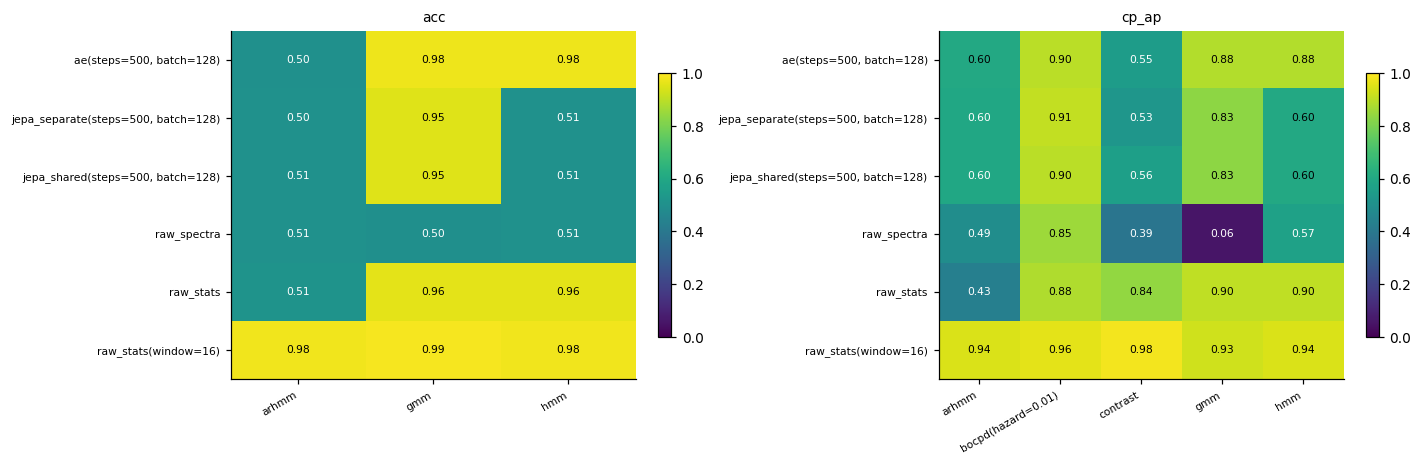

metric                                 acc                cp_ap                                          
detector_label                       arhmm    gmm    hmm  arhmm bocpd(hazard=0.01) contrast    gmm    hmm
features_label                                                                                           
ae(steps=500, batch=128)             0.504  0.975  0.975  0.602              0.898    0.551  0.883  0.883
jepa_separate(steps=500, batch=128)  0.504  0.951  0.507  0.597              0.907    0.526  0.829  0.604
jepa_shared(steps=500, batch=128)    0.506  0.951  0.507  0.597              0.898    0.564  0.829  0.604
raw_spectra                          0.507  0.500  0.507  0.489              0.852    0.388  0.056  0.574
raw_stats                            0.512  0.957  0.957  0.432              0.883    0.840  0.902  0.902
raw_stats(window=16)                 0.977  0.988  0.977  0.941              0.961    0.980  0.927  0.941

In [ ]:
# all feature learners x detectors (raw baselines and learnt features)
res = pd.concat([res_raw, res_learnt], ignore_index=True)
viz.plot_results(res)
res[(res.view == "features") & res.metric.isin(["acc", "cp_ap"])].pivot_table(
    index="features_label", columns=["metric", "detector_label"], values="value").round(3)

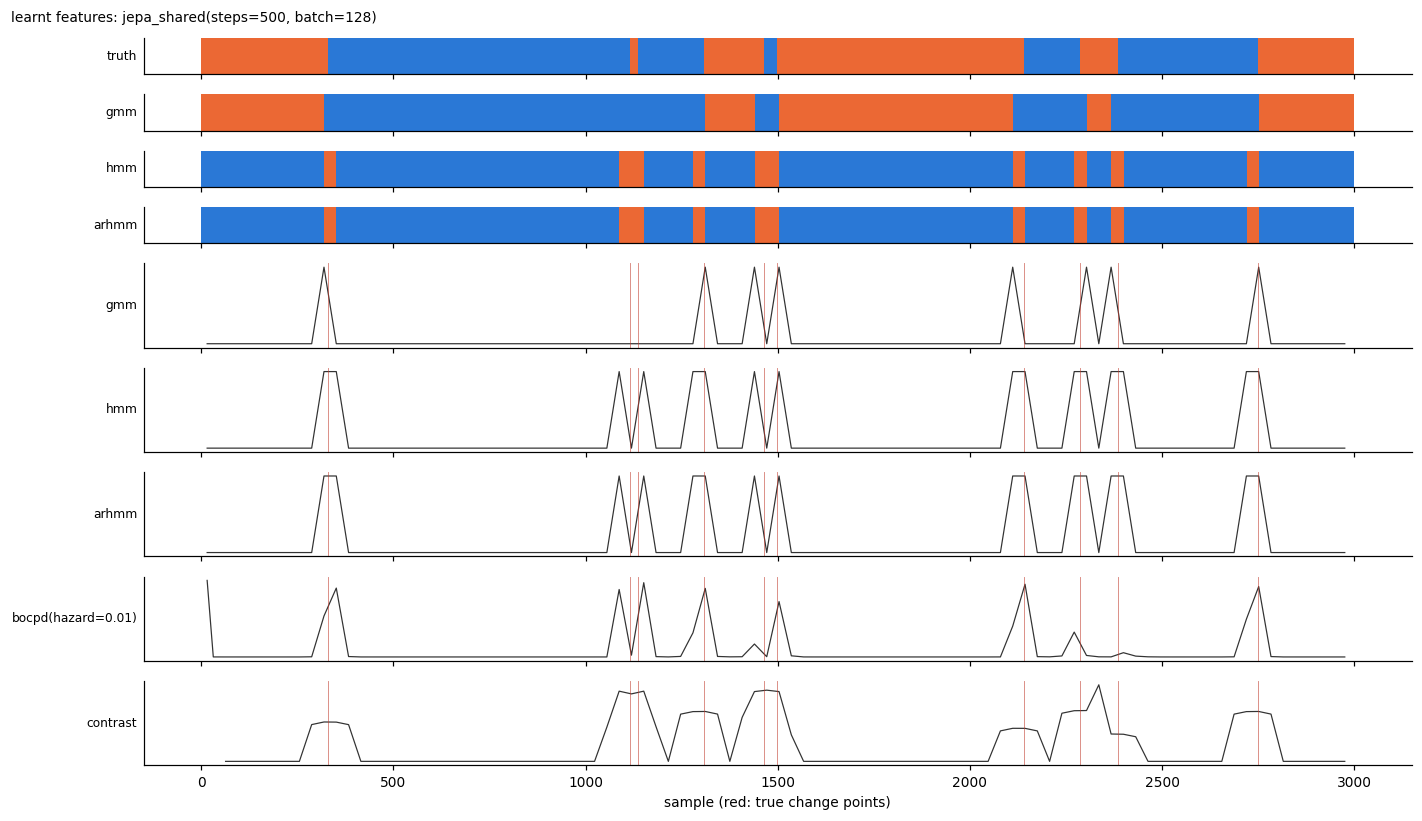

In [ ]:
# ✏️ decisions on one learnt feature learner
f = LEARNT[0]
dec, starts = bench.decisions(f)
viz.plot_decisions(data, dec, starts, f.window, ds.K, title=f"learnt features: {f.label()}", n=3000)

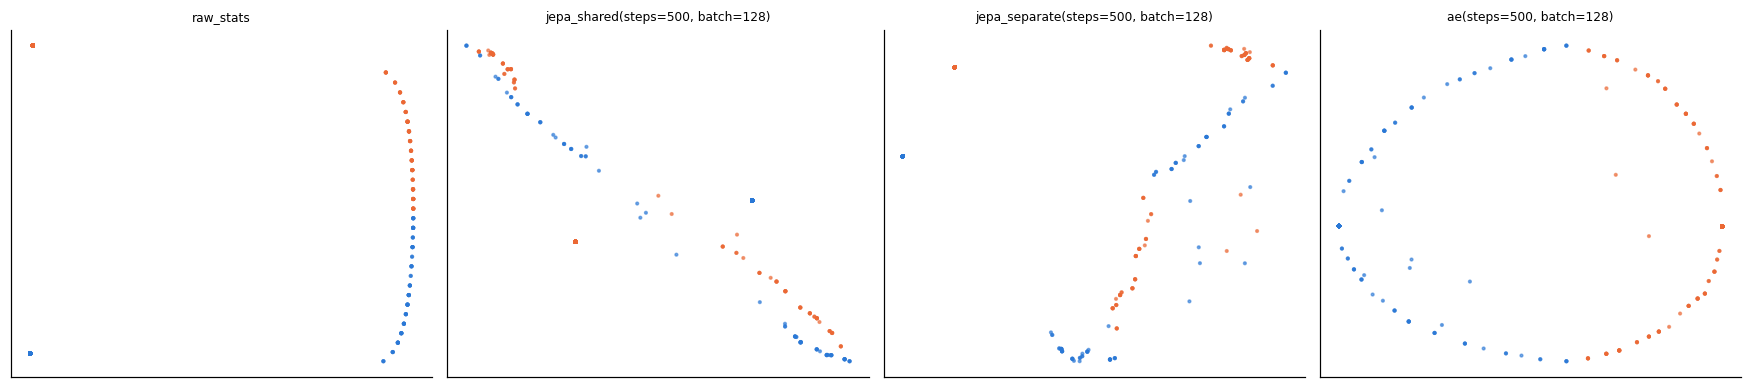

In [ ]:
# feature spaces: 2-D PCA of the window features, coloured by the true regime
views = {f.label(): bench.features(f)[0]["features"] for f in [RAW[0]] + LEARNT}
viz.plot_features(views, data, bench.features(RAW[0])[1], 32, ds.K)

In [ ]:
# separate-design JEPAs also expose their target encoder's features: the same detectors on that view
sep = [f for f in LEARNT if f.params.get("design", "shared") != "shared"]
if sep:
    t = res_learnt[(res_learnt.view == "target") & res_learnt.metric.isin(["acc", "cp_ap"])]
    display(t.pivot_table(index="features_label", columns=["metric", "detector_label"], values="value").round(3))

metric                                 acc                cp_ap                                          
detector_label                       arhmm    gmm    hmm  arhmm bocpd(hazard=0.01) contrast    gmm    hmm
features_label                                                                                           
jepa_separate(steps=500, batch=128)  0.504  0.951  0.507  0.609              0.898    0.541  0.829  0.604

## 4. Going further

- **Grids of datasets:** `cpbench.data.expand("my_grid.yaml")` returns one config per combination of the regime, signal, nuisance and corruption slots.
- **Difficulty audit:** `python -m cpbench.eval.audit --grid my_grid.yaml --jobs 2` runs the raw baselines and oracles on a whole grid (results in `cpbench_results/audit.csv`; see `benchmark_synthetic.ipynb`).
- **HPC sweeps:** `python -m cpbench.hpc.make_sweep cpbench/configs/sweep_first.yaml`, then `sbatch`, then `python -m cpbench.results.aggregate cpbench_runs cpbench_results/results.csv`.
- **Your own components:** register a source, transform, feature learner or detector (`@register_source`, `@register_transform`, `@register_learner`, `@register_detector`). It works in every cell above and, through `plugins=[module]`, on HPC.